In [1]:
# importing all libraries needed for ML module
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
import xgboost as xgb
import joblib
import warnings
warnings.filterwarnings('ignore')

print('All libraries imported!')

All libraries imported!


In [2]:
# loading stroke dataset
df = pd.read_csv(r'C:\Users\Ar\Desktop\multi-model-strok-prediction\data\stroke-dataset.csv')
print('Dataset shape:', df.shape)
print('Columns:', list(df.columns))

Dataset shape: (5110, 12)
Columns: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [3]:
# first look at data
df.head(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
print('Missing values:')
print(df.isnull().sum())
print('\nMissing percentage:')
print(round(df.isnull().sum() / len(df) * 100, 2))

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Missing percentage:
id                   0.00
gender               0.00
age                  0.00
hypertension         0.00
heart_disease        0.00
ever_married         0.00
work_type            0.00
Residence_type       0.00
avg_glucose_level    0.00
bmi                  3.93
smoking_status       0.00
stroke               0.00
dtype: float64


In [7]:
# filling missing bmi values with median
# median is better than mean because bmi has outliers
median_bmi = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(median_bmi)
print('Missing values after fix:', df.isnull().sum().sum())

Missing values after fix: 0


In [8]:
# id column is just identifier - not useful for prediction
df = df.drop(['id'], axis=1)
print('Shape after dropping id:', df.shape)

Shape after dropping id: (5110, 11)


In [9]:
print('Stroke distribution:')
print(df['stroke'].value_counts())
print('\nPercentage:')
print(round(df['stroke'].value_counts(normalize=True) * 100, 2))

Stroke distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Percentage:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


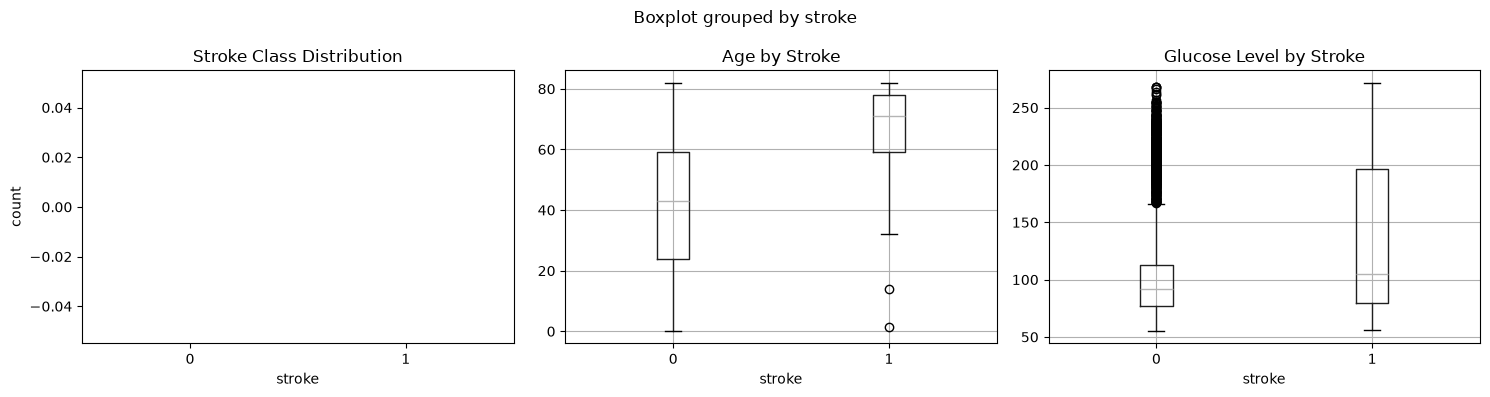

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# class distribution
sns.countplot(x='stroke', data=df, palette=['#1D9E75', '#D85A30'], ax=axes[0])
axes[0].set_title('Stroke Class Distribution')

# age distribution by stroke
df.boxplot(column='age', by='stroke', ax=axes[1])
axes[1].set_title('Age by Stroke')

# glucose distribution by stroke
df.boxplot(column='avg_glucose_level', by='stroke', ax=axes[2])
axes[2].set_title('Glucose Level by Stroke')

plt.tight_layout()
plt.show()

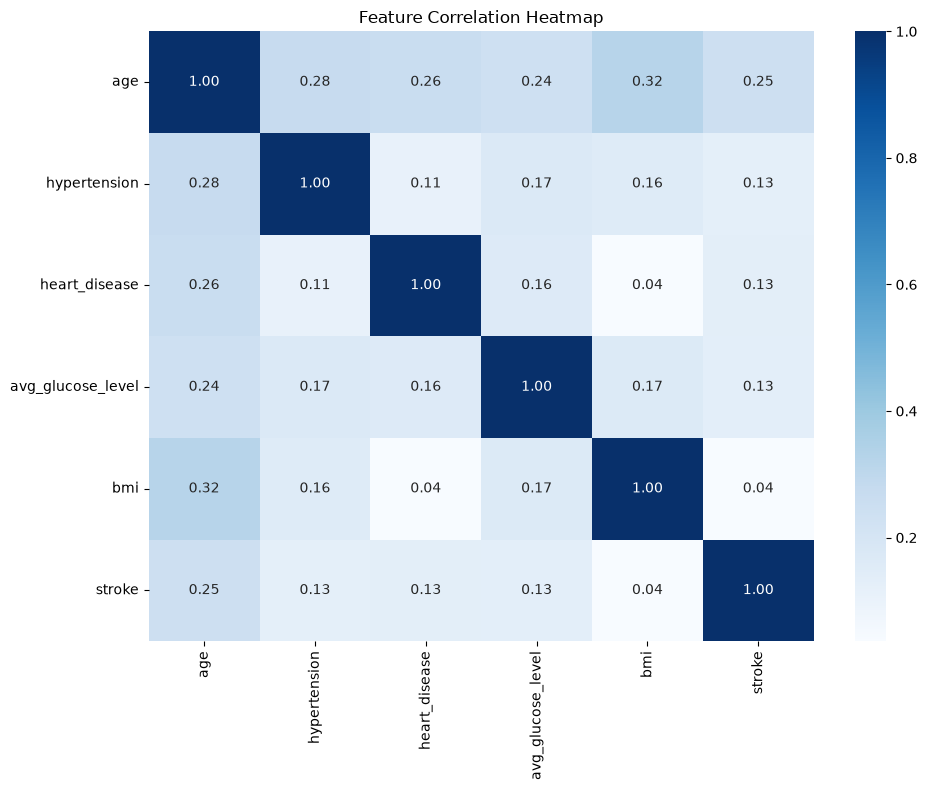

In [11]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [12]:
# one hot encoding for categorical columns
df_encoded = pd.get_dummies(df, columns=['gender', 'ever_married', 'work_type',
                                          'Residence_type', 'smoking_status'],
                             drop_first=True)
print('Shape before encoding:', df.shape)
print('Shape after encoding:', df_encoded.shape)
print('Columns:', list(df_encoded.columns))

Shape before encoding: (5110, 11)
Shape after encoding: (5110, 17)
Columns: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke', 'gender_Male', 'gender_Other', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


In [13]:
X = df_encoded.drop('stroke', axis=1)
y = df_encoded['stroke']
print('X shape:', X.shape)
print('y shape:', y.shape)
print('Feature names:', list(X.columns))

X shape: (5110, 16)
y shape: (5110,)
Feature names: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'gender_Other', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])
print('Training class balance:')
print(y_train.value_counts())

Training samples: 4088
Testing samples: 1022
Training class balance:
stroke
0    3889
1     199
Name: count, dtype: int64


In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Scaling done')

Scaling done


In [16]:
# SMOTETomek is better than simple SMOTE
# SMOTE creates synthetic samples + Tomek removes overlapping samples
smote_tomek = SMOTETomek(random_state=42)
X_train_resampled, y_train_resampled = smote_tomek.fit_resample(X_train_scaled, y_train)

print('Before SMOTETomek:', y_train.value_counts().to_dict())
print('After SMOTETomek:', y_train_resampled.value_counts().to_dict())

  File "c:\Users\Ar\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 268, in _count_physical_cores
    cpu_count_physical = sum(map(int, cpu_info))
                         ^^^^^^^^^^^^^^^^^^^^^^^


Before SMOTETomek: {0: 3889, 1: 199}
After SMOTETomek: {0: 3858, 1: 3858}


In [17]:
# training 4 different models to compare
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    'Voting Ensemble': VotingClassifier(estimators=[
        ('lr', LogisticRegression(random_state=42, max_iter=1000)),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', xgb.XGBClassifier(random_state=42, eval_metric='logloss'))
    ], voting='soft')
}

results = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    results[name] = {
        'Accuracy': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision': round(precision_score(y_test, y_pred) * 100, 2),
        'Recall': round(recall_score(y_test, y_pred) * 100, 2),
        'F1 Score': round(f1_score(y_test, y_pred) * 100, 2),
        'AUC': round(roc_auc_score(y_test, y_pred_proba), 3)
    }
    trained_models[name] = model
    print(f'{name} trained!')

print('\nAll models trained!')

Logistic Regression trained!
Random Forest trained!
XGBoost trained!
Voting Ensemble trained!

All models trained!


In [18]:
results_df = pd.DataFrame(results).T
print('Model Comparison:')
print(results_df)

Model Comparison:
                     Accuracy  Precision  Recall  F1 Score    AUC
Logistic Regression     74.85      13.94    80.0     23.74  0.845
Random Forest           91.29      14.55    16.0     15.24  0.771
XGBoost                 93.64      25.81    16.0     19.75  0.786
Voting Ensemble         90.70      15.38    20.0     17.39  0.821


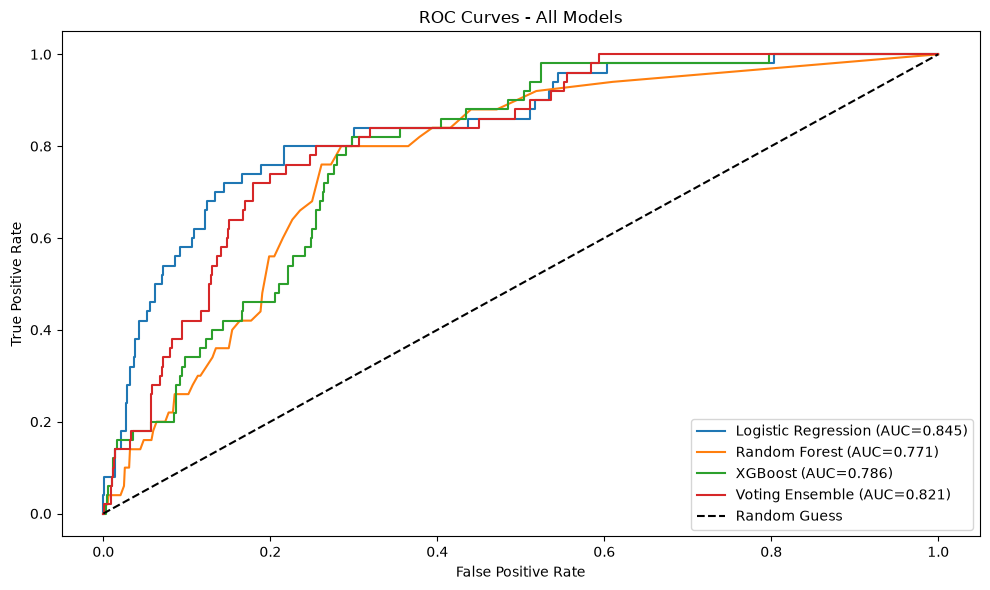

In [19]:
plt.figure(figsize=(10, 6))

for name, model in trained_models.items():
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    auc = roc_auc_score(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models')
plt.legend()
plt.tight_layout()
plt.show()

Best Model (XGBoost) Confusion Matrix:
True Negative: 949
False Positive: 23
False Negative: 42
True Positive: 8


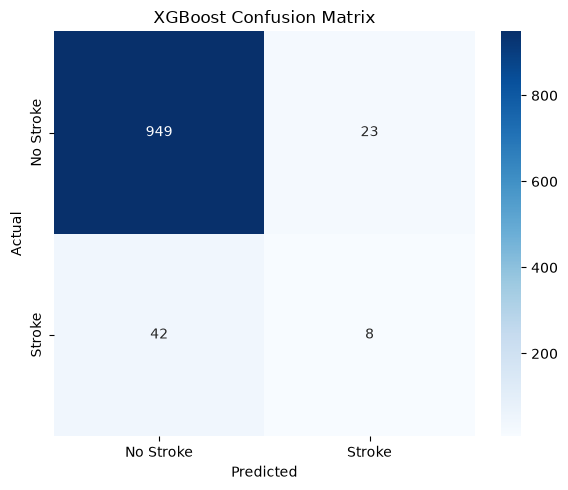

In [20]:
# XGBoost is usually best - using it for confusion matrix
best_model = trained_models['XGBoost']
y_pred_best = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm.ravel()

print('Best Model (XGBoost) Confusion Matrix:')
print(f'True Negative: {tn}')
print(f'False Positive: {fp}')
print(f'False Negative: {fn}')
print(f'True Positive: {tp}')

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Stroke', 'Stroke'],
            yticklabels=['No Stroke', 'Stroke'])
plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

                           Feature    Importance
0                              age  3.668564e-01
1                avg_glucose_level  1.300330e-01
2                              bmi  1.264949e-01
3                 ever_married_Yes  8.487930e-02
4             Residence_type_Urban  4.897111e-02
5                      gender_Male  4.865802e-02
6                work_type_Private  3.742769e-02
7                     hypertension  3.266575e-02
8      smoking_status_never smoked  2.993713e-02
9          work_type_Self-employed  1.994609e-02
10           smoking_status_smokes  1.893398e-02
11              work_type_children  1.874989e-02
12  smoking_status_formerly smoked  1.870439e-02
13                   heart_disease  1.773582e-02
14          work_type_Never_worked  6.520805e-06
15                    gender_Other  4.776132e-08


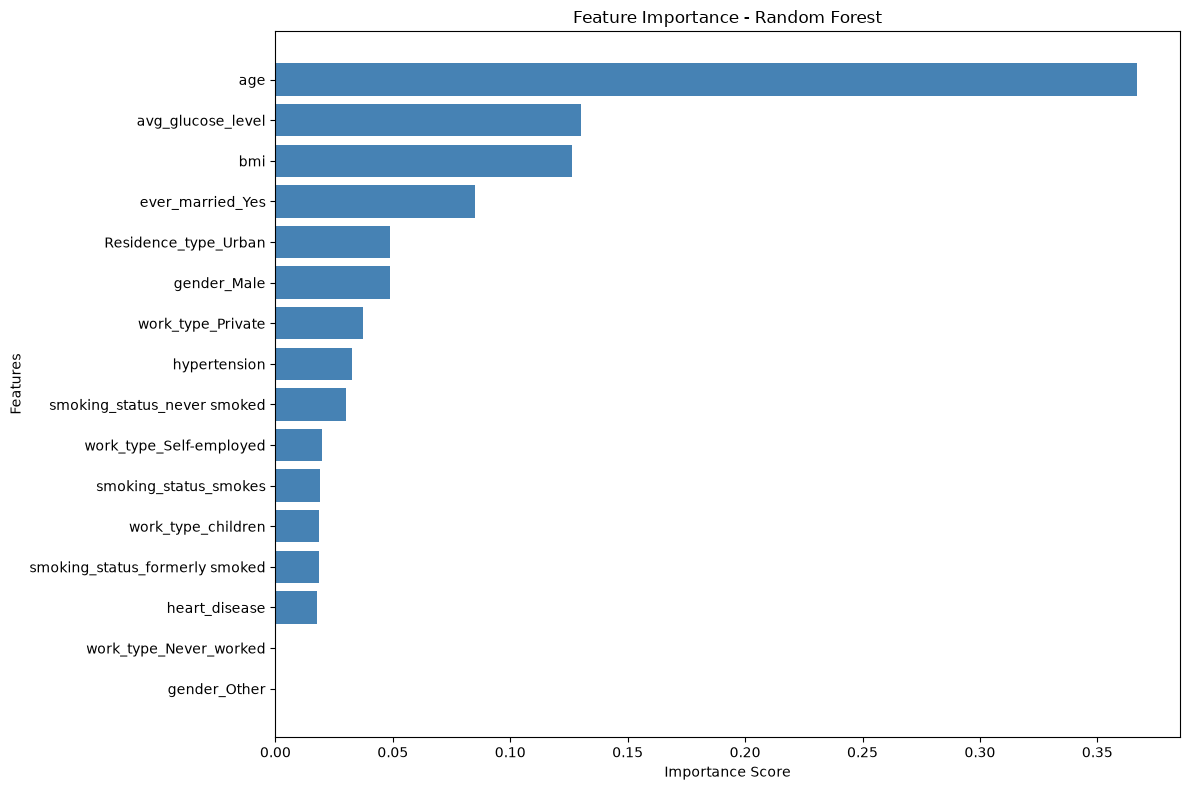

In [21]:
# feature importance using Random Forest instead of SHAP
importances = trained_models['Random Forest'].feature_importances_
feature_names = list(X.columns)

feat_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print(feat_df)

plt.figure(figsize=(12, 8))
plt.barh(feat_df['Feature'], feat_df['Importance'], color='steelblue')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [22]:
# saving best model and scaler
joblib.dump(trained_models['XGBoost'], r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\best_ml_model.pkl')
joblib.dump(scaler, r'C:\Users\Ar\Desktop\multi-model-strok-prediction\models\scaler.pkl')
print('Best ML model saved!')
print('Scaler saved!')

Best ML model saved!
Scaler saved!
